# Service areas and closest facilities

In the previous section, we calculated the travel times from one origin to all nodes of a street network. The same idea can be used to answer two questions that come up in many GIS analyses. First, which area can be reached from a given location within a given time? For example, a city planner might want to know which neighborhoods are within a 10-minute walk from a new library. Second, which one of several facilities, such as grocery stores, schools or fire stations, is the closest one to a given location, and how long does it take to get there? The first question is answered with a **service area** analysis and the second one with a **closest facility** analysis. In this section, we go through both of them. We also show how to calculate the travel time to the closest facility for every cell of a population grid by walking, cycling and driving. Representing travel times in a grid like this is useful, because all cells have the same size and shape: the travel times by different travel modes can be compared with each other cell by cell, and they can be combined with other data stored in the same grid, such as the number of inhabitants. The Helsinki Region Travel Time Matrix that we used in Chapter 6.10 is an example of such data.

In this section, we study how easily the people living in the Helsinki metropolitan area can reach grocery stores. As in Chapter 8.2, we use `pyrosm` to read the OpenStreetMap data for the four cities of the metropolitan area from a PBF file:

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx
import osmnx as ox
import pandas as pd
from pyrosm import OSM, get_data_by_geocoding

places = [
    "Helsinki, Finland",
    "Espoo, Finland",
    "Vantaa, Finland",
    "Kauniainen, Finland",
]
fp = get_data_by_geocoding(places)
osm = OSM(fp)

/var/folders/f2/pgp09jl542zffhtrt2hx8zhh0000gp/T/ipykernel_9742/3024928095.py:14: UserWarning: Movisda FI-18 leaves out 0.096 km² (0.0064 %) of the area. This part lies within the bounds [24.831, 59.901, 24.918, 59.919].
  fp = get_data_by_geocoding(places)


Next, we read the street network for walking and build a `networkx` graph out of it in the same way as in Chapter 8.2. The walking network contains also footways and other paths, so it is considerably larger than the driving network that we used in Chapter 8.2, and reading it takes a bit longer. Many of the paths in the Helsinki region are shared by pedestrians and cyclists. In OpenStreetMap, such paths are typically tagged as cycle ways (`highway=cycleway`), and a `foot` tag tells whether pedestrians may use them (e.g. `foot=designated`). For the cycle ways that do not have a `foot` tag, the `shared_paths` parameter decides whether they are included in the walking network. With `shared_paths="local"` (the default), `pyrosm` follows the default rules of the country where the path is located, and in Finland, pedestrians may use cycle ways. With `"tagged"`, these cycle ways are left out, and with `"all"`, they are included in every country:

In [2]:
nodes, edges = osm.get_network(network_type="walking", shared_paths="local", nodes=True)
G_walk = osm.to_graph(nodes, edges, graph_type="networkx")
G_walk

Reading area_helsinki-finland_espoo-finland_vantaa-finland_kauniainen-finland.osm.pbf: building the edges:  33…

Building the NetworkX graph: keeping the largest connected part:   2%|1         | 00:02<01:46

Unlike for driving, there are no speed limits that we could use for walking. Hence, we assume that people walk at a constant speed of 5 km/h on all streets. We store this speed in the `speed_kph` attribute of every edge with the `nx.set_edge_attributes()` function, after which we can calculate the travel times with the same `ox.routing.add_edge_travel_times()` function that we used in Chapter 8.2:

In [3]:
nx.set_edge_attributes(G_walk, 5, name="speed_kph")
G_walk = ox.routing.add_edge_travel_times(G_walk)

Now each edge of the graph has a travel time in seconds in its `travel_time` attribute. Notice also that `pyrosm` builds the walking graph so that every street can be walked in both directions, i.e. the travel time from A to B is the same as from B to A.

## Service areas

A **service area** is the area that can be reached from a given location, such as a facility, within a given travel time or distance along the network. Let's find out which areas can be reached within 15 minutes of walking from the Helsinki Central Railway Station. We first find the node that is closest to the station in the same way as in Chapter 8.2. Then we use the `nx.ego_graph()` function, which returns a subgraph that contains all the nodes that can be reached from a given node within a given `radius`. With the `distance` parameter, we tell the function to measure the radius with the `travel_time` attribute of the edges, which means that the radius is given in seconds:

In [4]:
station_x, station_y = 24.941, 60.171
station_node = ox.distance.nearest_nodes(G_walk, X=station_x, Y=station_y)

G_15min = nx.ego_graph(G_walk, station_node, radius=15 * 60, distance="travel_time")
G_15min

As a result, we get a new graph that contains only the part of the street network that can be reached within 15 minutes from the station. Under the hood, `nx.ego_graph()` uses Dijkstra's algorithm in the same way as the `nx.single_source_dijkstra_path_length()` function that we used in Chapter 8.2, but it stops the search when the travel time exceeds the given radius. To turn the reached streets into an area, we extract the edges of the subgraph as a GeoDataFrame, reproject them into a metric coordinate reference system (here ETRS-GK25, EPSG:3879), create a 50 meter buffer around each street and merge the buffers into a single polygon with the `.union_all()` method (see Chapter 6.3). Let's do this for travel times of 15, 10 and 5 minutes, and store the resulting areas in a GeoDataFrame together with their size in square kilometers:

In [5]:
service_areas = []
for minutes in [15, 10, 5]:
    G_area = nx.ego_graph(
        G_walk, station_node, radius=minutes * 60, distance="travel_time"
    )
    area_edges = ox.graph_to_gdfs(G_area, nodes=False).to_crs(epsg=3879)
    area = area_edges.buffer(50).union_all()
    service_areas.append({"minutes": minutes, "geometry": area})

service_areas = gpd.GeoDataFrame(service_areas, crs="EPSG:3879")
service_areas["area_km2"] = service_areas.area / 1_000_000
service_areas[["minutes", "area_km2"]]

,minutes,area_km2
0,15,3.385410
1,10,1.589749
2,5,0.388409


As we can see, the area that can be reached grows quickly with the travel time. Let's plot the service areas on top of the streets that can be reached within 15 minutes. Because the largest area is the first row of the GeoDataFrame, the smaller areas are drawn on top of it:

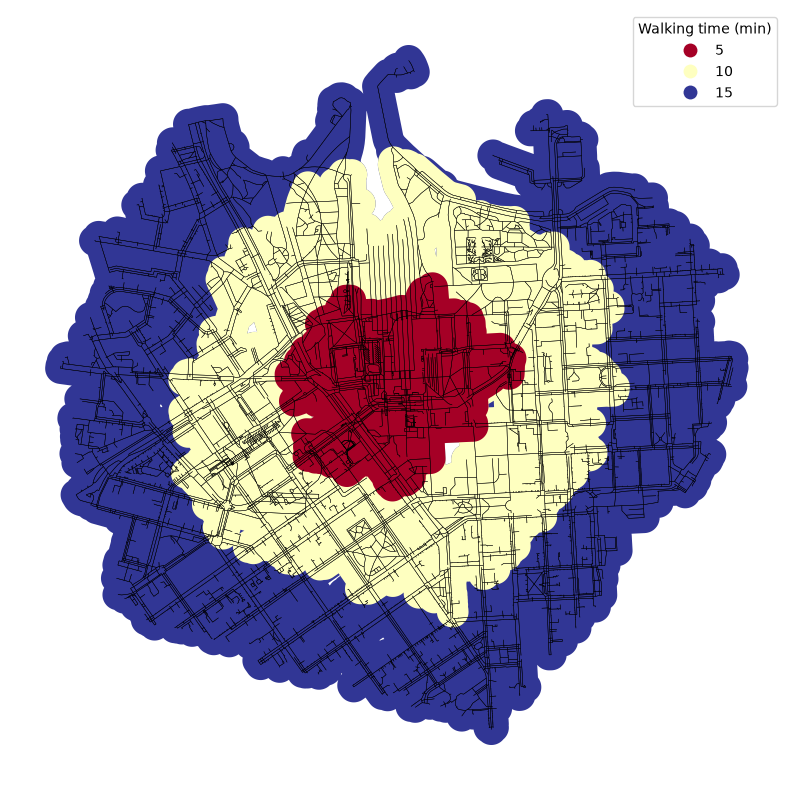

In [6]:
streets_15min = ox.graph_to_gdfs(G_15min, nodes=False).to_crs(epsg=3879)

ax = service_areas.plot(
    column="minutes",
    categorical=True,
    cmap="RdYlBu",
    legend=True,
    legend_kwds={"title": "Walking time (min)"},
    figsize=(10, 10),
)
ax = streets_15min.plot(ax=ax, color="black", linewidth=0.3)
ax.set_axis_off()

_**Figure 8.X.** Areas that can be reached within 5, 10 and 15 minutes of walking from the Helsinki Central Railway Station._

As we can see in Figure 8.X, the service areas are not circles, because their shape follows the street network around the station.

## Closest facility analysis

In a **closest facility** analysis, we find the closest facility for each location from a group of facilities, together with the travel time (or distance) to it. Let's find the closest grocery store for every node of our walking network. `pyrosm` can read also other data than street networks from the PBF file. Here, we read the supermarkets, i.e. the features that are tagged with `shop=supermarket` in OpenStreetMap, with the `.get_pois()` method:

In [7]:
stores = osm.get_pois(custom_filter={"shop": ["supermarket"]})
stores.geom_type.value_counts()

Point      147
Polygon     52
Name: count, dtype: int64

As we can see, most of the supermarkets are stored as points, but some of them are stored as polygons that represent the outline of the store building. To find the nearest nodes for the stores, we need points, so let's convert the polygons into points by calculating their centroids. Because the centroids should be calculated in a projected coordinate reference system (see Chapter 6.4), we first reproject the data into EPSG:3879 and then convert the centroids back to WGS84, which is the coordinate reference system of our graph:

In [8]:
store_points = stores.to_crs(epsg=3879).centroid.to_crs(epsg=4326)
len(store_points)

199

Next, we find the nearest node for each store. The `ox.distance.nearest_nodes()` function accepts also lists or arrays of coordinates, in which case it returns the nearest nodes for all of them at once:

In [9]:
store_nodes = ox.distance.nearest_nodes(G_walk, X=store_points.x, Y=store_points.y)
store_nodes[:5]

array([ 1066514122,   803820982,  4733703149,  3249914165, 12015169262])

Now we could find the closest store for each node by running a separate search from every node of the network, and picking the store with the shortest travel time. With more than 400,000 nodes in our network, this would take a long time. A much faster option is to turn the problem around and start a single search from all the stores at the same time. This is what the `nx.multi_source_dijkstra_path_length()` function does: the search spreads out from all the stores simultaneously, and each node is reached first from the store that is closest to it. As a result, we get the travel time to the closest store for every node of the network in one go. Because the travel times in our walking graph are the same in both directions, it does not matter that the search starts from the stores. We pass the store nodes to the function as a set, which removes the duplicates in case two stores share the same nearest node:

In [10]:
walk_times = nx.multi_source_dijkstra_path_length(
    G_walk, sources=set(store_nodes), weight="travel_time"
)
len(walk_times)

407785

As a result, we get a dictionary in the same format as in Chapter 8.2: the keys are the node ids and the values are the travel times (in seconds) to the closest store. If you also want to know which store is the closest one, you can use the `nx.multi_source_dijkstra()` function, which returns also the shortest paths: the first node of each path is the node of the closest store.

## Travel times on a population grid

Next, let's attach the travel times to the population grid of the Helsinki Region Environmental Services Authority (HSY) that we used in Chapter 6.7. The grid consists of 250 x 250 meter cells, and it contains the number of inhabitants living in each cell:

In [11]:
pop_grid = gpd.read_file("data/Population_grid_2021_HSY.gpkg")
pop_grid.tail(2)

,id,inhabitants,occupancy_rate,geometry
5851,Vaestotietoruudukko_2021.5852,6,2.417000e+01,"POLYGON ((25513499.996 6685499, 25513499.996 6..."
5852,Vaestotietoruudukko_2021.5853,30427,1.000000e+09,"POLYGON ((25514000 6659998.998, 25514000 66602..."


Notice the number of inhabitants in the last row: over 30,000 people in a single cell. This is a special cell that HSY has placed in the sea in the south-eastern corner of the area, and it contains the inhabitants who cannot be linked to any building, such as people living in institutions. Because this cell does not represent a real place, let's remove it by its `id`:

In [12]:
pop_grid = pop_grid.loc[pop_grid["id"] != "Vaestotietoruudukko_2021.5853"]
len(pop_grid)

5852

To find the travel time for each grid cell, we use the center point of the cell to represent it. We calculate the centroids of the cells (the grid is already in a projected coordinate reference system), convert them to WGS84 and find the nearest node of the walking network for each centroid. Then we look up the travel time of each node from the `walk_times` dictionary with the `.map()` method, and convert the travel times into minutes:

In [13]:
centroids = pop_grid.centroid.to_crs(epsg=4326)
pop_grid["walk_node"] = ox.distance.nearest_nodes(G_walk, X=centroids.x, Y=centroids.y)
pop_grid["walk_time"] = pop_grid["walk_node"].map(walk_times) / 60
pop_grid[["inhabitants", "walk_node", "walk_time"]].head()

,inhabitants,walk_node,walk_time
0,5,960691021,199.062024
1,7,957014542,168.316368
2,8,12345841677,141.058248
3,7,12345841666,138.656124
4,11,12393520244,127.777236


Now each grid cell has the id of its nearest node and the walking time (in minutes) to the closest grocery store. The first rows of the data are located at the western edge of Espoo, far away from the closest grocery store, which is why their walking times are more than two hours. Here, we ignore the short distance from the center of the cell to its nearest node, which is typically only a few tens of meters. Let's see how the walking times look on a map. We set the color scale to range from 0 to 30 minutes with the `vmin` and `vmax` parameters, which means that all cells with a walking time of 30 minutes or more get the same color:

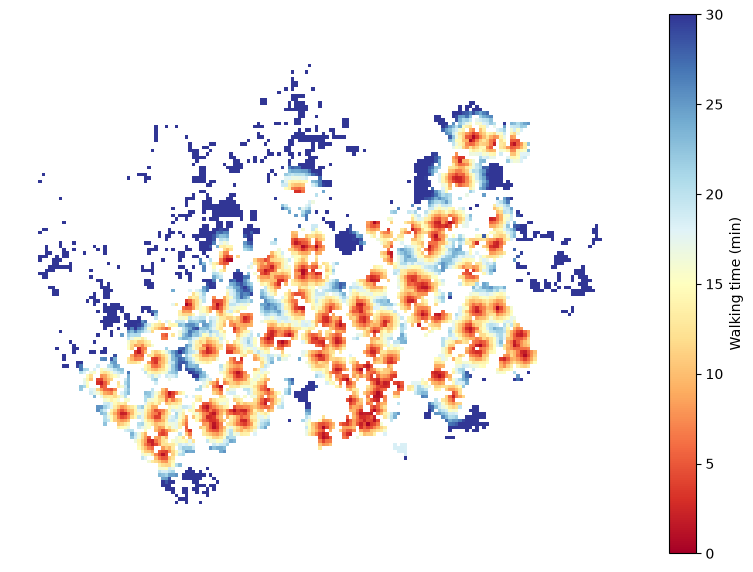

In [14]:
ax = pop_grid.plot(
    column="walk_time",
    cmap="RdYlBu",
    vmin=0,
    vmax=30,
    linewidth=0,
    legend=True,
    legend_kwds={"label": "Walking time (min)"},
    figsize=(10, 7),
)
ax.set_axis_off()

_**Figure 8.X.** Walking time (in minutes) to the closest grocery store from each populated 250 x 250 meter grid cell in the Helsinki metropolitan area._

As we can see, the grid cells with short walking times form clusters around the grocery stores, whereas in the outer parts of the area, the closest store can be more than half an hour away on foot.

### Comparing walking, cycling and driving

Let's now calculate the same travel times by cycling and driving, so that we can compare the travel modes with each other. Because the steps are the same for each travel mode, let's put them into a function. There is one difference to the walking network: the cycling and driving graphs are directed, because they take the one-way streets into account (see Chapter 8.2). If we started the search from the stores, we would get the travel times *from* the stores *to* the grid cells. To get the travel times in the opposite direction, i.e. from the homes to the stores, we reverse the direction of all edges with the `.reverse()` method of the graph before the search:

In [15]:
def travel_time_to_closest(G, facility_points, grid):
    """
    Returns the travel time (in minutes) from the centroid of each grid cell
    to the closest facility, using the travel_time attribute of the edges.
    """
    facility_nodes = ox.distance.nearest_nodes(
        G, X=facility_points.x, Y=facility_points.y
    )
    travel_times = nx.multi_source_dijkstra_path_length(
        G.reverse(), sources=set(facility_nodes), weight="travel_time"
    )
    centroids = grid.centroid.to_crs(epsg=4326)
    grid_nodes = ox.distance.nearest_nodes(G, X=centroids.x, Y=centroids.y)
    return pd.Series(grid_nodes, index=grid.index).map(travel_times) / 60

Now we can read the cycling network, assume a constant cycling speed of 15 km/h, and calculate the travel times to the closest store. In the cycling network, the `shared_paths` parameter works the other way around: it decides which footways without a `bicycle` tag are included. In Finland, cyclists may not use footways by default, so with the default `"local"`, the cycling network includes only the footways that are tagged as open for bicycles (e.g. `bicycle=yes`):

In [16]:
nodes, edges = osm.get_network(network_type="cycling", nodes=True)
G_bike = osm.to_graph(nodes, edges, graph_type="networkx")
nx.set_edge_attributes(G_bike, 15, name="speed_kph")
G_bike = ox.routing.add_edge_travel_times(G_bike)

pop_grid["bike_time"] = travel_time_to_closest(G_bike, store_points, pop_grid)

Reading area_helsinki-finland_espoo-finland_vantaa-finland_kauniainen-finland.osm.pbf: writing the result:  59…

Building the NetworkX graph: keeping the largest connected part:   2%|1         | 00:02<01:46

For driving, we use the speed limits of the streets. As in Chapter 8.2, we fill in the missing speed limits with the `ox.routing.add_edge_speeds()` function before calculating the travel times:

In [17]:
nodes, edges = osm.get_network(network_type="driving", nodes=True)
G_drive = osm.to_graph(nodes, edges, graph_type="networkx")
G_drive = ox.routing.add_edge_speeds(G_drive)
G_drive = ox.routing.add_edge_travel_times(G_drive)

pop_grid["drive_time"] = travel_time_to_closest(G_drive, store_points, pop_grid)

Let's compare the travel times of the three travel modes:

In [18]:
pop_grid[["walk_time", "bike_time", "drive_time"]].describe().round(1)

,walk_time,bike_time,drive_time
count,5852.0,5852.0,5852.0
mean,22.0,7.5,2.9
std,23.6,7.8,2.4
min,0.1,0.0,0.0
25%,9.1,3.2,1.4
50%,14.8,5.1,2.3
75%,23.4,7.9,3.5
max,199.1,69.2,21.8


As we can see, the walking times are considerably longer than the cycling and driving times. The maximum values show that some of the populated grid cells are located far away from any grocery store, in the rural parts of the area.

Let's also plot the travel times of the three travel modes side by side, using the same color scale as above:

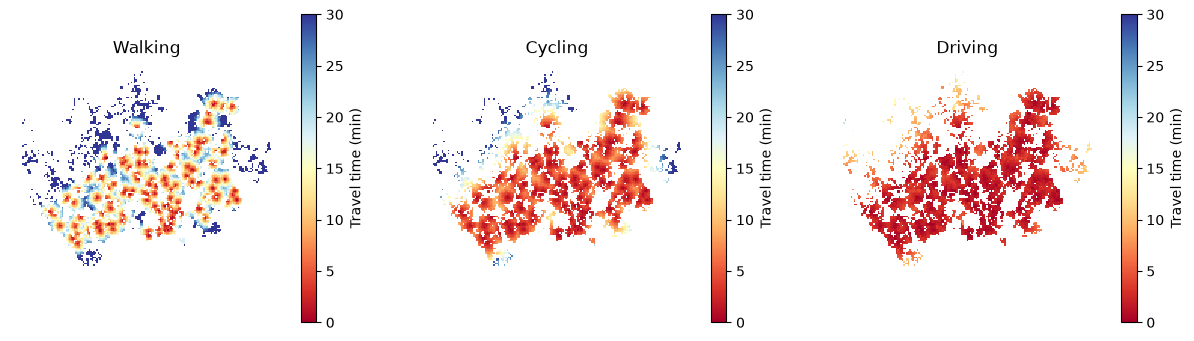

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
titles = {"walk_time": "Walking", "bike_time": "Cycling", "drive_time": "Driving"}

for ax, (column, title) in zip(axes, titles.items()):
    pop_grid.plot(
        ax=ax,
        column=column,
        cmap="RdYlBu",
        vmin=0,
        vmax=30,
        linewidth=0,
        legend=True,
        legend_kwds={"label": "Travel time (min)"},
    )
    ax.set_title(title)
    ax.set_axis_off()

_**Figure 8.X.** Travel time (in minutes) to the closest grocery store by walking, cycling and driving._

Figure 8.X shows that by bike, most of the populated grid cells are within a few minutes from the closest grocery store, and by car, almost all of them are. Notice that the driving times are optimistic, because we assume that people drive at the speed limit all the way, and we do not consider the time that it takes e.g. to walk to the car or to park it.

Because the travel times are stored in the same grid as the number of inhabitants, we can combine them directly. For instance, we can calculate the share of the inhabitants who can reach a grocery store within 10 minutes with each travel mode:

In [20]:
total_inhabitants = pop_grid["inhabitants"].sum()

for column, title in titles.items():
    within_10min = pop_grid.loc[pop_grid[column] <= 10, "inhabitants"].sum()
    print(f"{title}: {within_10min / total_inhabitants:.0%} of the inhabitants")

Walking: 51% of the inhabitants
Cycling: 97% of the inhabitants
Driving: 100% of the inhabitants


As we can see, almost all inhabitants can reach a grocery store within 10 minutes by bike or by car, whereas on foot, only about half of them can. Measures like this are commonly used in accessibility analysis, which we will discuss in more detail in Chapter 11.

In this section, we learned how to find the area that can be reached from a location within a given travel time, and how to calculate the travel time to the closest facility for a large number of locations at once. We also attached the travel times to a population grid, which makes it possible to compare the travel modes with each other and to combine the travel times with other data. There are also more specialized network problems related to facilities and routes, such as finding the best order in which to visit several locations (the traveling salesman problem), planning the routes of a fleet of delivery vehicles (the vehicle routing problem), or choosing the best locations for new facilities (location-allocation problems). These are beyond the scope of this book, but you can find tools for them for example in `networkx` (the `nx.approximation.traveling_salesman_problem()` function) and in the `spopt` library[^spopt]. In the next section, we move on to other common network operations, starting with the connectivity of networks.

## Footnotes

[^spopt]: <https://pysal.org/spopt/>